# Check TnpB copy number per MAG

In [36]:
import os
import pandas as pd
from Bio import Seq,SeqIO,AlignIO
import numpy as np
import bz2
import gzip
import logomaker
from collections import Counter
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib import colors
import matplotlib.image as image
from matplotlib import ticker
import matplotlib as mpl
%matplotlib inline
%config InlineBackend.figure_format = 'png'
plt.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['figure.dpi']= 500

## Make tree with TnpBs from Xiang *et al*., 2023

In [6]:
Xiang_TnpBs = pd.read_csv('../data/TnpBs_Xiang_2023.csv', sep='\t')

In [7]:
Xiang_TnpBs = Xiang_TnpBs.assign(WT_Sequence = Xiang_TnpBs['Sequence'].apply(lambda x: x.replace(
    'MGSPKKKRKVEF', '').replace('GSKRPAATKKAGQAKKKKTGYPYDVPDYAYPYDVPDYAYPYDVPDYA', '')))

In [8]:
Xiang_Seq = [SeqIO.SeqRecord(Seq.Seq(Xiang_TnpBs.loc[i, 'WT_Sequence']), id=Xiang_TnpBs.loc[i, 'Name'], name='',
                            description='') for i in Xiang_TnpBs.index]

In [10]:
ISDra2_seq = '''MIRNKAFVVRLYPNAAQTELINRTLGSARFVYNHFLARRIAAYKESGKGLTYGQTSSELT
LLKQAEETSWLSEVDKFALQNSLKNLETAYKNFFRTVKQSGKKVGFPRFRKKRTGESYRT
QFTNNNIQIGEGRLKLPKLGWVKTKGQQDIQGKILNVTVRRIHEGHYEASVLCEVEIPYL
PAAPKFAAGVDVGIKDFAIVTDGVRFKHEQNPKYYRSTLKRLRKAQQTLSRRKKGSARYG
KAKTKLARIHKRIVNKRQDFLHKLTTSLVREYEIIGTEHLKPDNMRKNRRLALSISDAGW
GEFIRQLEYKAAWYGRLVSKVSPYFPSSQLCHDCGFKNPEVKNLAVRTWTCPNCGETHDR
DENAALNIRREALVAAGISDTLNAHGGYVRPASAGNGLRSENHATLVV'''.replace('\n', '')

In [11]:
ISDra2 = [SeqIO.SeqRecord(Seq.Seq(ISDra2_seq), id='ISDra2', name='', description='')]

## Check conserved residues

In [12]:
Xiang_IDs = set([s.id for s in Xiang_Seq])

In [15]:
Xiang_active_Ecoli = ['ISMmu1', 'ISBth16', 'ISEfa4', 'ISDra2', 'ISCpe2', 'ISMac7', 'ISEc46', 'ISAeme8', 'ISRor9',
                      'ISDge10', 'ISNsp3', 'ISNsp2', 'ISTel2', 'ISMma22', 'ISHahl1', 'ISSen6', 'ISEc44',
                      'ISAs26', 'ISKpn69', 'ISEc41', 'ISAba30', 'ISTfu1', 'ISClte2', 'ISBce3', 'ISCco1']

In [17]:
Xiang_active_seq = [rec for rec in Xiang_Seq if rec.id in Xiang_active_Ecoli]

#### Make sequence logo and check for other conserved residues

In [18]:
SeqIO.write(Xiang_active_seq + ISDra2, 'Xiang_active_TnpB.faa', 'fasta')

25

`mmseqs easy-cluster Xiang_active_TnpB.faa Xiang_active_TnpB_80 tmp -c 0.80 --cov-mode 0 --min-seq-id 0.80 --threads 8 --cluster-reassign`

In [19]:
!muscle5.1 -align Xiang_active_TnpB_80_rep_seq.fasta -output Xiang_active_TnpB_80_aln.faa


muscle 5.1.linux64 [12f0e2]  1584Gb RAM, 192 cores
Built Jan 13 2022 23:17:13
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 23 seqs, avg length 392, max 434

00:00 4.0Mb  CPU has 192 cores, defaulting to 20 threads
00:01 1.4Gb   100.0% Calc posteriors
00:01 1.4Gb   100.0% Consistency (1/2)
00:01 1.4Gb   100.0% Consistency (2/2)
00:01 1.4Gb   100.0% UPGMA5           
00:01 1.4Gb   100.0% Refining


In [20]:
!trimal -in Xiang_active_TnpB_80_aln.faa -out Xiang_active_TnpB_80_aln_trimmed.faa -gappyout

In [21]:
!hmmbuild Xiang_active_TnpB_80_aln_trimmed.hmm Xiang_active_TnpB_80_aln_trimmed.faa

# hmmbuild :: profile HMM construction from multiple sequence alignments
# HMMER 3.3.2 (Nov 2020); http://hmmer.org/
# Copyright (C) 2020 Howard Hughes Medical Institute.
# Freely distributed under the BSD open source license.
# - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -
# input alignment file:             Xiang_active_TnpB_80_aln_trimmed.faa
# output HMM file:                  Xiang_active_TnpB_80_aln_trimmed.hmm
# - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -

# idx name                  nseq  alen  mlen eff_nseq re/pos description
#---- -------------------- ----- ----- ----- -------- ------ -----------
1     Xiang_active_TnpB_80_aln_trimmed    23   356   356     2.11  0.590 

# CPU time: 0.17u 0.00s 00:00:00.17 Elapsed: 00:00:00.17


In [22]:
!hmmlogo Xiang_active_TnpB_80_aln_trimmed.hmm > Xiang_active_TnpB_80_aln_trimmed_logo_data.txt

In [23]:
logo_info = [line for line in open('Xiang_active_TnpB_80_aln_trimmed_logo_data.txt', 'r')]

In [24]:
logo_info = [l for l in logo_info if len(l.split(' '))>10]
logo_info = [l.split(':')[1].split('(')[0] for l in logo_info]
logo_info = [[float(x) for x in l.split(' ') if len(x)>0] for l in logo_info]

In [25]:
logo_info = pd.DataFrame(logo_info)
aa = 'ACDEFGHIKLMNPQRSTVWY'
logo_info.columns = list(aa)

In [26]:
total_info_by_position = logo_info.sum(axis=1)

In [27]:
aln = {s.id:s for rec in AlignIO.parse('Xiang_active_TnpB_80_aln_trimmed.faa', 'fasta')
       for s in rec}

In [28]:
# check if the aln len is the same
len(total_info_by_position) == len(aln['ISDra2'])

True

In [29]:
# for each position in the alignment, get the relative frequency of each aa
aa_freq_by_pos = []
for i in range(len(total_info_by_position)):
    all_observed_aa = Counter([aln[ID][i] for ID in aln if aln[ID][i]!='-'])
    for a in aa:
        if a not in all_observed_aa:
            all_observed_aa[a] = 0
    all_observed_aa = pd.Series(all_observed_aa).loc[list(aa)]
    aa_freq_by_pos.append(all_observed_aa.divide(all_observed_aa.sum()))
aa_freq_by_pos = pd.concat(aa_freq_by_pos, axis=1).transpose()

In [30]:
filtered_info = [aa_freq_by_pos.loc[i]*total_info_by_position.loc[i] for i in range(
    len(total_info_by_position))]

In [31]:
filtered_info = pd.concat(filtered_info, axis=1).transpose()

In [32]:
max_height = logo_info.sum(axis=1).max()
n_pos_per_row = 89
n_rows = logo_info.shape[0]//n_pos_per_row + int(logo_info.shape[0]%n_pos_per_row>0)

In [33]:
conserved_positions = aa_freq_by_pos[(aa_freq_by_pos>=0.9).apply(any, axis=1)]

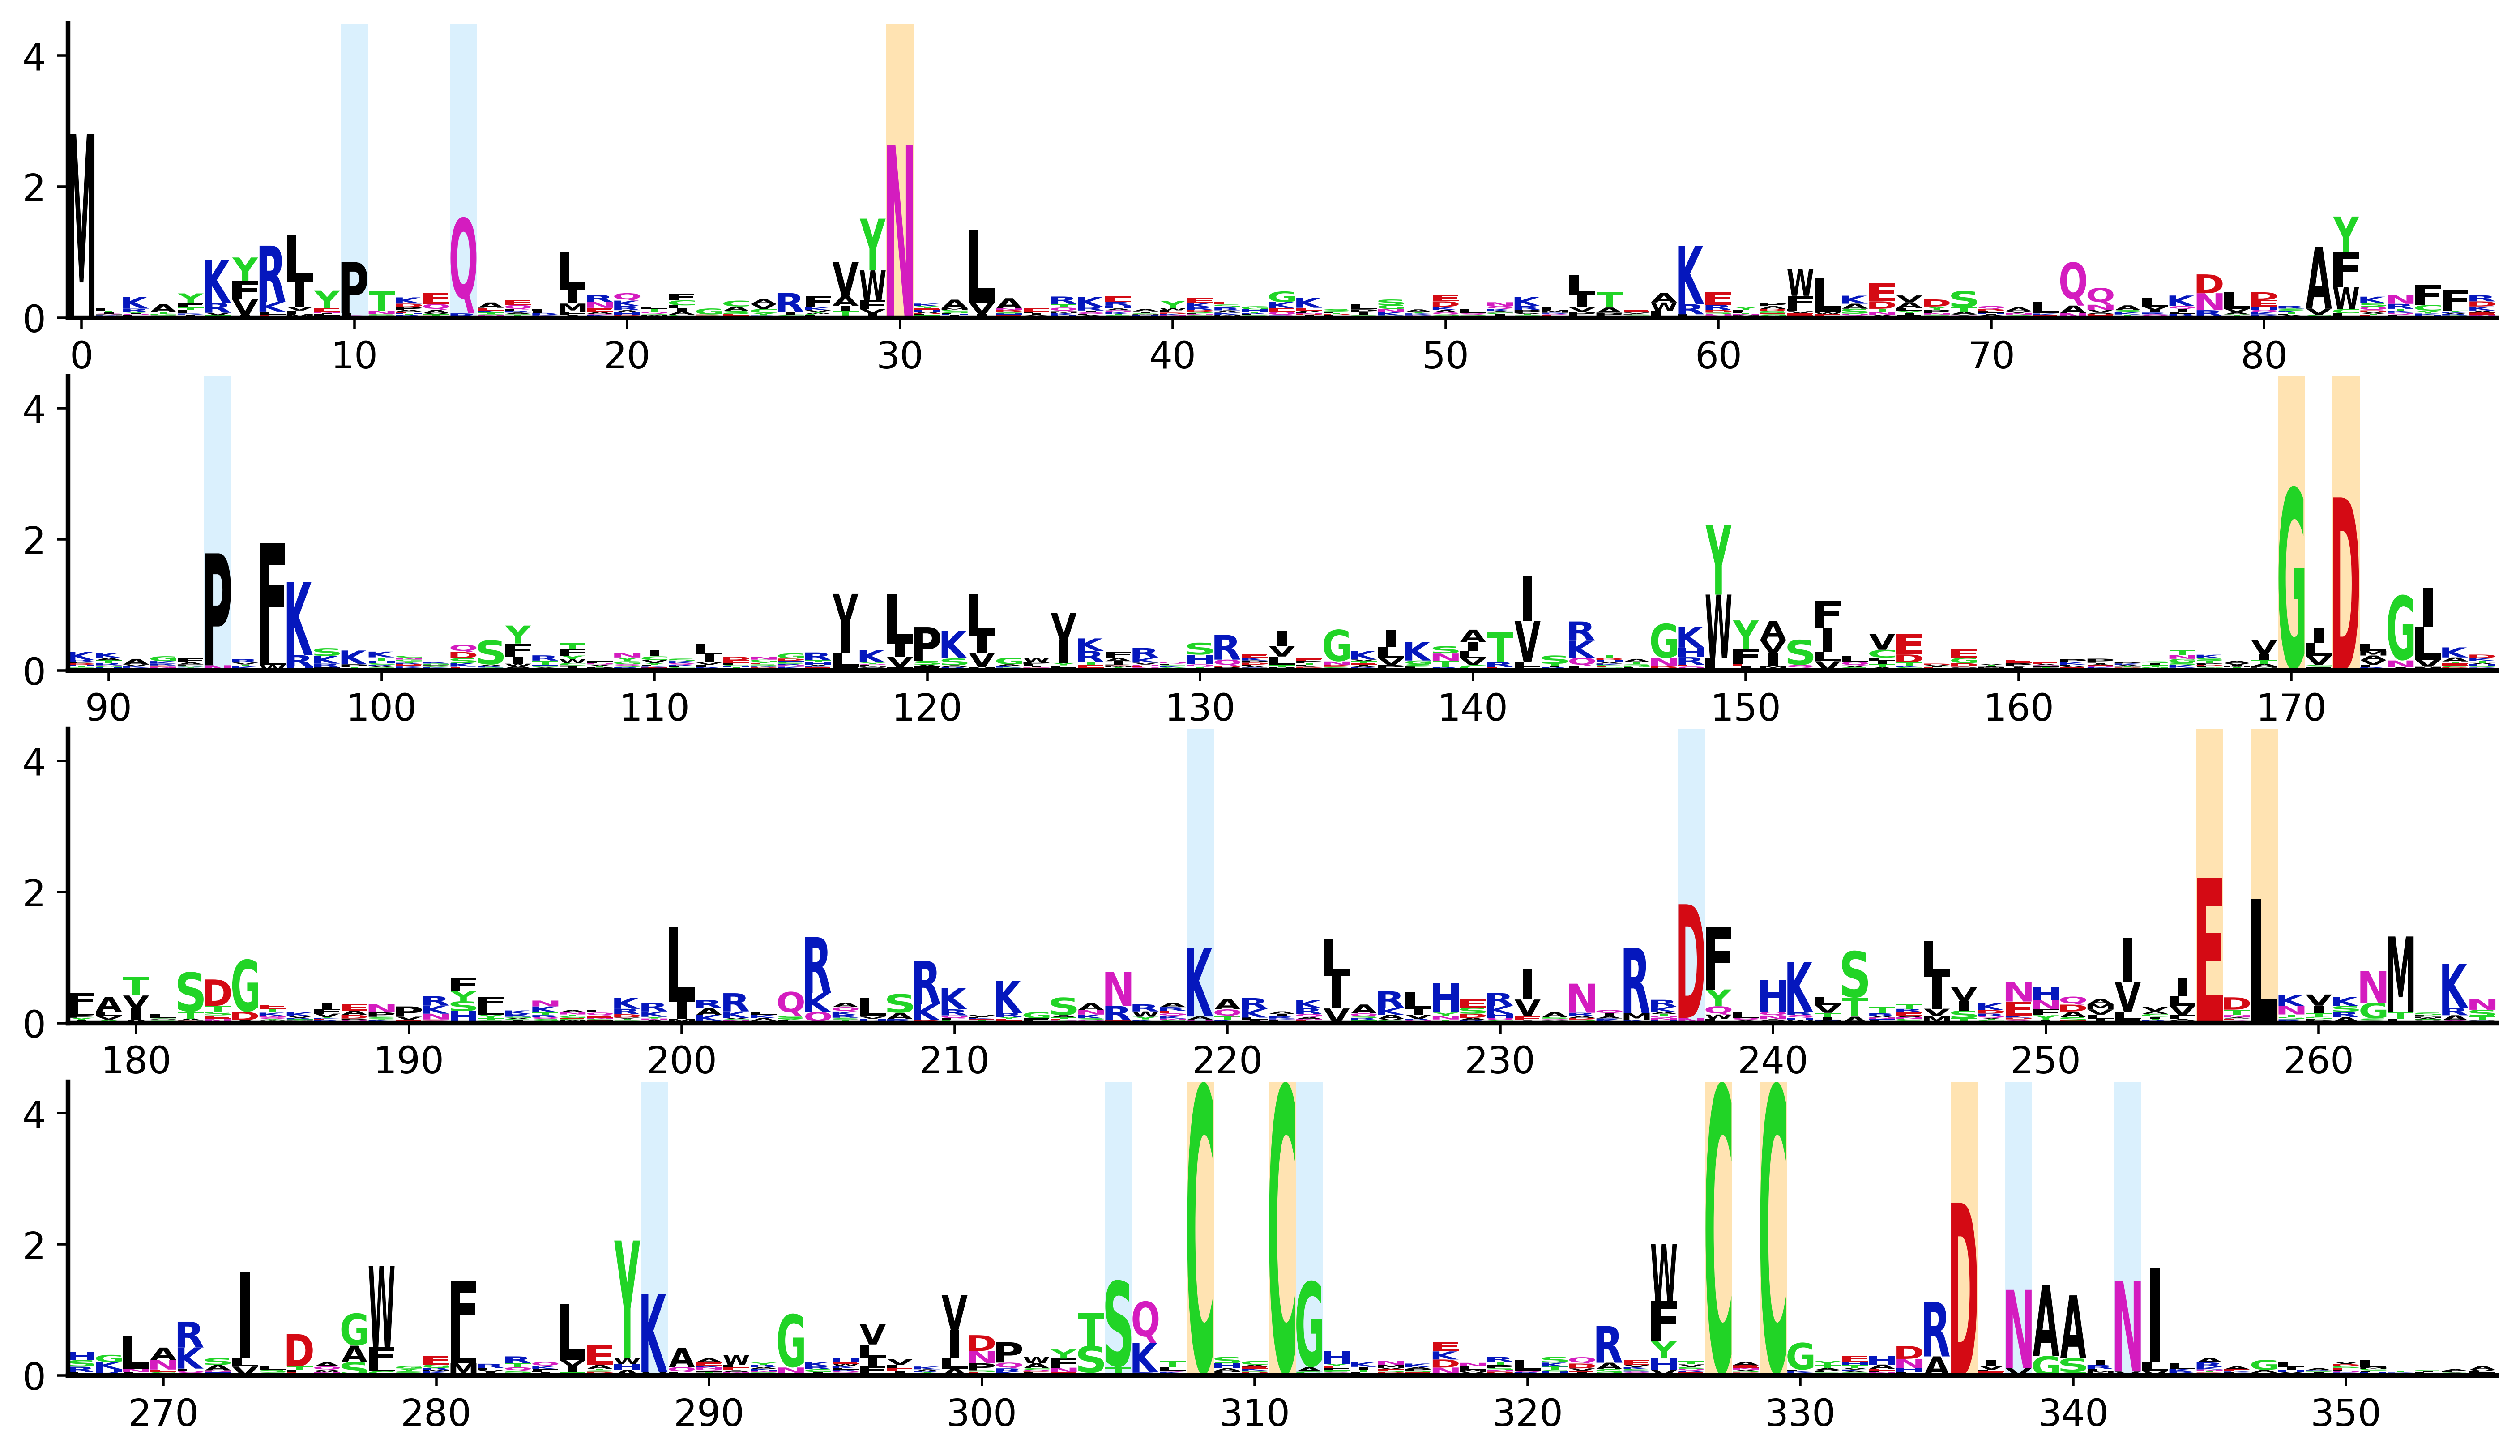

In [37]:
fig, axes = plt.subplots(nrows=n_rows, ncols=1, figsize=(14, 2*n_rows))

lwd = 1.5
fontsize = 12

for i in range(n_rows):
    ax = axes[i]
    seq_logo = logomaker.Logo(filtered_info[i*n_pos_per_row:(i+1)*n_pos_per_row], ax=ax)
    ax.set_xlim(i*n_pos_per_row-0.5,(i+1)*n_pos_per_row-0.5)
    ax.set_ylim(0,max_height)
    # style using Logo methods
    seq_logo.style_spines(visible=False)
    seq_logo.style_spines(spines=['left', 'bottom'], visible=True)

    for y in ax.get_yticklabels():
        y.set_size(fontsize)
    for x in ax.get_xticklabels():
        x.set_size(fontsize)

    ax.spines['bottom'].set_linewidth(lwd)
    ax.spines['left'].set_linewidth(lwd)
    
# add annotations
alpha = 0.3
Xiang_positions = [30, 172, 170, 256, 258, 336, 327, 329, 308, 311]
all_positions = conserved_positions.index[1:]

for p in all_positions:
    if p in Xiang_positions:
        axes[p//n_pos_per_row].add_patch(mpatches.Rectangle((p-0.5, 0), 1, max_height, color='orange',
                                                        alpha=alpha, zorder=-1, linewidth=0))
    else:
        axes[p//n_pos_per_row].add_patch(mpatches.Rectangle((p-0.5, 0), 1, max_height, color='lightskyblue',
                                                        alpha=alpha, zorder=-1, linewidth=0))

plt.subplots_adjust()
plt.show()